# Analyse ROMY Events

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sixdegrees import sixdegrees

## Configurations

In [2]:
config = {
    # Required time window parameters
    'tbeg': "2025-03-31 10:30:00",  # Start time
    'tend': "2025-03-31 13:30:00",  # End time

    # event
    'origin_time': "2025-03-31 12:00:00",
    'magnitude': 5.2,

    # Station coordinates (required)
    'station_lon': -90.77424,  # LIGO LIGO longitude
    'station_lat': 30.56289,    # LIGO LIGO latitude

    # SEED identifiers
    'seed': "XX.LIV..",     # Default seed ID
    'rot_seed': ["LI.LIV.IY.DJX", "LI.LIV.IX.DJY"], # Rotation sensor seed ID
    'tra_seed': ["LI.LIV.IX.DHZ", "LI.LIV.IX.DHX", "LI.LIV.IX.DHY"],  # Translation sensor seed ID
        # Data source
    'data_source': "mseed_file",  # "fdsn" | "sds" | "mseed_file"

    # Path to local mseed file
    'path_to_mseed_file': "./data/2025_03_31.mseed",  # "./data/eventM62_6c.mseed",

    # Path to SDS for rotation and translation data
    # 'path_to_sds_rot': "/home/andbro/freenas/temp_archive/",    # SDS path for rotation data
    # 'path_to_sds_tra': "/home/andbro/bay200/mseed_online/archive/",  # SDS path for translation data

    # Path to inventory of rotation and translation sensor
    'path_to_inv_rot': "./metadata/station_LI_LIV.xml",  # Rotation station inventory
    'path_to_inv_tra': "./metadata/station_LI_LIV.xml",  # Translation station inventory

    # Remove response of translation data
    'tra_remove_response': True,
    'tra_output': "VEL",

    # Resample rate
    'resample_rate': 20,  # Hz

    # Path to figures
    'path_to_figures': "./figures/",

    # dummy traces
    'dummy_trace': ["LI.LIV.IX.DJZ"],

    # Path configurations
    'workdir': "./",            # Working directory
    'path_to_data_out': "./output/",  # Output directory

    # Set rotation of components
    'rotate_zne': False,

    # Project information
    'project': "BRS_Analysis'",  # Project name

    # Rotational units
    'runit': 'rad',          # Rotational units
    'tunit': 'm/s',          # Translational units

    # Optional parameters
    'verbose': True,            # Print detailed information
}

In [3]:
# from obspy import read

# st = read(config['path_to_mseed_file'])


# st.select(station="LIV")

# print(st.__str__(extended=True))

Setup a sixdegrees object

In [4]:
sd = sixdegrees(conf=config)

Store the configuration as a pickle file

In [5]:
# sd.store_as_pickle(config, "./event_configs/"+f"M{str(config['magnitude']).replace('.','')}_{config['tbeg'][:10].replace('-','')}")

Get key information about the event

In [6]:
ev = sd.get_event_info(origin_time=config['origin_time'],
                       base_catalog="USGS",
                       magnitude=config['magnitude'])

ev = {
    "backazimuth": 300.0,
    "distance_km": 0.0,
}

Error getting event information from USGS:
No data available for request.
HTTP Status code: 204
Detailed response of server:




This will load the data from the data source:
- local mseed file
- local sds system
- fdsn (online)

and trim it to the time window

In [7]:
sd.load_data(config['tbeg'], config['tend'], config['resample_rate'])

-> fetching LI.LIV.IX.DHZ data from mseed file
-> fetching LI.LIV.IX.DHX data from mseed file
-> fetching LI.LIV.IX.DHY data from mseed file
-> translation inventory provided: metadata/station_LI_LIV.xml
-> removing response: VEL
3 Trace(s) in Stream:
LI.LIV.IX.DHZ | 2025-03-31T10:29:59.000000Z - 2025-03-31T13:30:01.000000Z | 512.0 Hz, 5530625 samples
LI.LIV.IX.DHX | 2025-03-31T10:29:59.000000Z - 2025-03-31T13:30:01.000000Z | 512.0 Hz, 5530625 samples
LI.LIV.IX.DHY | 2025-03-31T10:29:59.000000Z - 2025-03-31T13:30:01.000000Z | 512.0 Hz, 5530625 samples
-> fetching LI.LIV.IY.DJX data from mseed file
-> fetching LI.LIV.IX.DJY data from mseed file
-> adding dummy trace: LI.LIV.IX.DJZ
-> rotation inventory provided: metadata/station_LI_LIV.xml
3 Trace(s) in Stream:
LI.LIV.IY.DJX | 2025-03-31T10:29:59.000000Z - 2025-03-31T13:30:01.000000Z | 256.0 Hz, 2765313 samples
LI.LIV.IX.DJY | 2025-03-31T10:29:59.000000Z - 2025-03-31T13:30:01.000000Z | 256.0 Hz, 2765313 samples
LI.LIV.IX.DJZ | 2025-03-3

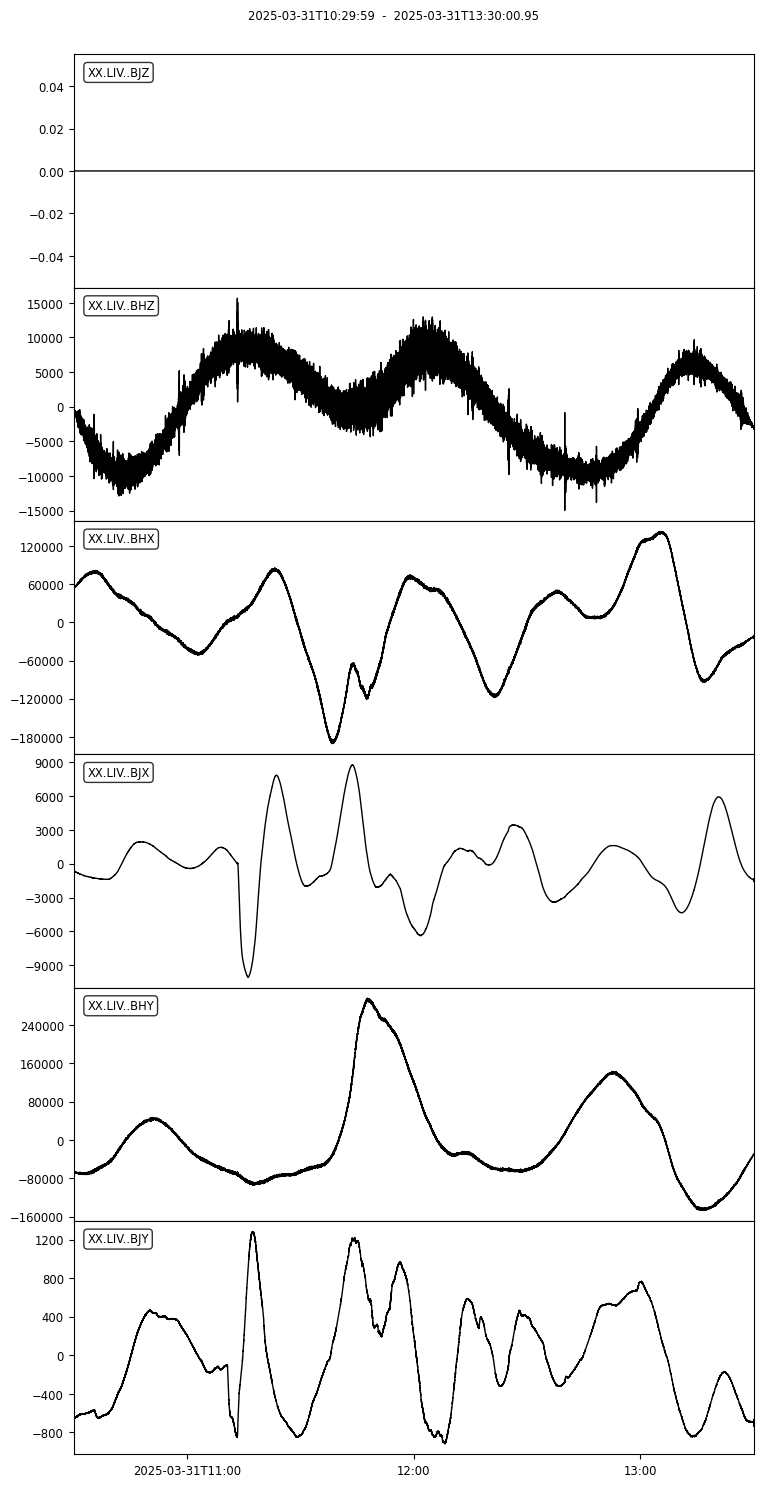

In [8]:
sd.st.plot(equal_scale=False);

Ensure that all traces of stream have the same sample size

In [9]:
sd.trim_stream(set_common=True, set_interpolate=False)

### Rotate data to ZNE

In [10]:
# as in file
IX = 162.2835
IY = 252.2835

code = "B"

from obspy.signal.rotate import rotate2zne

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*JY")[0].data, IX, 0,
    sd.st.select(station="LIV", channel="*JX")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*JZ")[0].data, 0, 90
)
sd.st.select(station="LIV", channel="*JX")[0].data = E
sd.st.select(station="LIV", channel="*JX")[0].stats.channel = code+"JE"

sd.st.select(station="LIV", channel="*JY")[0].data = N
sd.st.select(station="LIV", channel="*JY")[0].stats.channel = code+"JN"

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*HY")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*HX")[0].data, IX, 0,
    sd.st.select(station="LIV", channel="*HZ")[0].data, 0, -90
)
sd.st.select(station="LIV", channel="*HX")[0].data = E
sd.st.select(station="LIV", channel="*HX")[0].stats.channel = code+"HE"

sd.st.select(station="LIV", channel="*HY")[0].data = N
sd.st.select(station="LIV", channel="*HY")[0].stats.channel = code+"HN"


In [11]:
# correct amplitudes from paul which has it in nanorad and nanometer/s

for tr in sd.st:
    if "H" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9
    elif "J" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9


In [12]:
sd.correct_tilt()

### Wavelet Comparsion

In [13]:
# # First compute CWT for all components
# cwt_results = {}
# for comp in ['Z', 'N', 'E']:

#     try:
#         # Rotation components
#         rot_data = sd.get_stream("rotation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Rotation"] = sd.compute_cwt(
#             rot_data.times(), rot_data.data, rot_data.stats.delta,
#             normalize=True
#         )

#         del rot_data
#     except:
#         print(f"No {comp} data for rotation")
#     try:
#         # Translation components
#         acc_data = sd.get_stream("translation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Translation"] = sd.compute_cwt(
#             acc_data.times(), acc_data.data, acc_data.stats.delta,
#             normalize=True
#         )

#         del acc_data
#     except:
#         print(f"No {comp} data for translation")


In [14]:
# # Then plot all components
# fig = sixdegrees.plot_cwt_all(
#     rot=sd.get_stream("rotation"),
#     acc=sd.get_stream("translation"),
#     cwt_output=cwt_results,
#     clog=True,
#     ylim=1
# )

## Analysis

In [29]:
# Parameters
fmin, fmax = 0.015, 0.03

fcenter = np.round(np.sqrt(fmax*fmin), 2)
print(fcenter)

T = 2 * int(1/fcenter)
print(T)

overlap = 0.75

cc_threshold = 0.7

0.02
100


Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [30]:
sd.filter_data(fmin=fmin, fmax=fmax, output=False)

Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [31]:
sd.polarity_stream(pol_dict={"HZ": 1, "JZ": 1}, raw=True)

-> polarity already applied. Exiting...


In [32]:
sd.st.trim(starttime=sd.tbeg+200, endtime=sd.tend-4000)

6 Trace(s) in Stream:
XX.LIV..BHE | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BHN | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BHZ | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJN | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJZ | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJE | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples

In [33]:
# get cross-correlation function of JT and HZ and find the lag
from obspy.signal.cross_correlation import correlate, xcorr_max
from obspy.signal.rotate import rotate_ne_rt

JN = sd.get_stream("rotation").select(channel="*N")[0].data
JE = sd.get_stream("rotation").select(channel="*E")[0].data

JR, JT = rotate_ne_rt(JN, JE, ev['backazimuth'])

HZ = sd.get_stream("translation").select(channel="*Z")[0].data

cc0_before = correlate(JT, HZ, 0)

cc = correlate(JT, HZ, len(JT))

lag, cc_max = xcorr_max(cc)

HZ = np.roll(HZ, lag)

cc0_after = correlate(JT, HZ, 0)

print(lag, cc_max, cc0_before, cc0_after)

# sd.st.select(channel="*Z")[0].data = HZ



-34980 0.5181223821496094 [-0.33584285] [0.51754916]


let's compare the waveforms of the rotation (red) and translational (black) components 

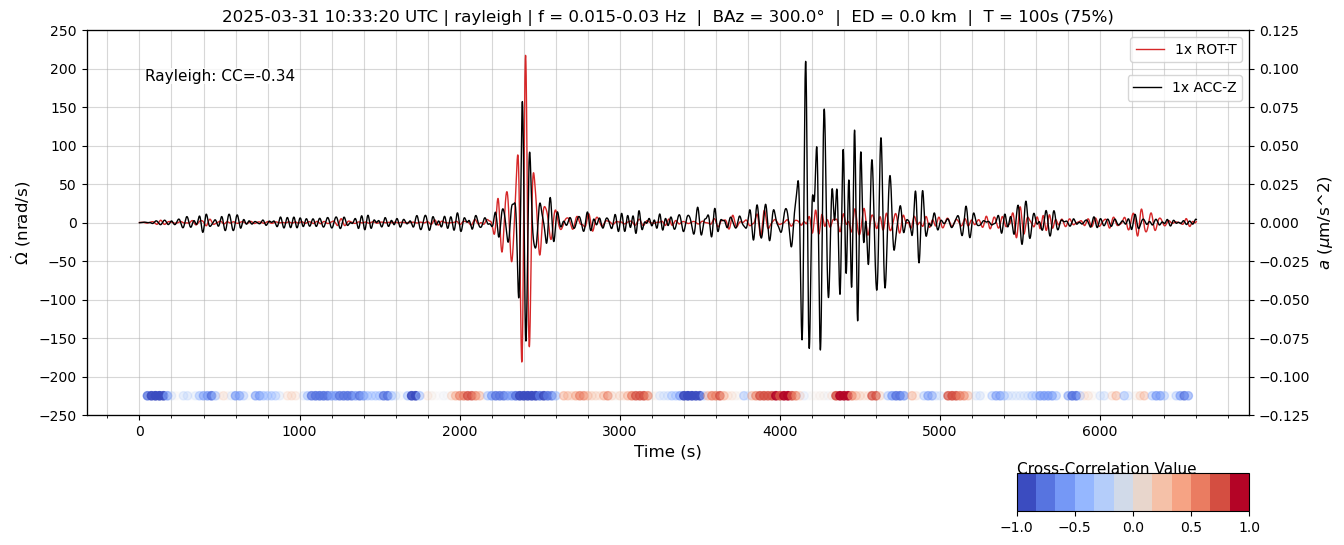

In [34]:
fig = sd.plot_waveform_cc(
    rot0=sd.get_stream("rotation"),
    acc0=sd.get_stream("translation"),
    baz=ev['backazimuth'],
    distance=ev['distance_km'],
    fmin=fmin,
    fmax=fmax,
    twin_sec=T,
    twin_overlap=overlap,
    wave_type="rayleigh",
)

fig.savefig(f"{config['path_to_figures']}tornado_waveform_cc.png", bbox_inches='tight')


In [35]:
# fig = sd.plot_spectra_comparison_fill(rot=sd.get_stream("rotation"), 
#                                       acc=sd.get_stream("translation"),
#                                       fmin=0.09, fmax=0.6,
#                                       ylog=False, xlog=False, fill=True
#                                       )

### Backazimuth Estimate

In [36]:
# compute backazimuth
baz_results = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=1,
    baz_win_sec=T,
    baz_win_overlap=overlap,
    out=True
)


baz_max = 73, baz_std = 92


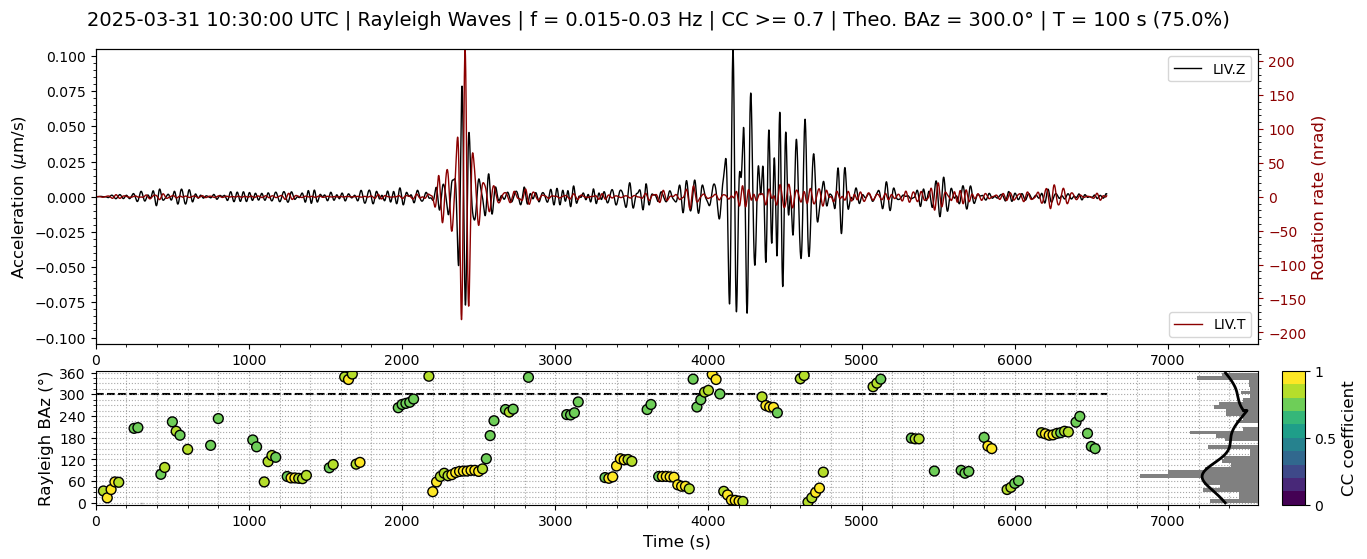

In [37]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='max',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}tornado_backazimuth_max.png", bbox_inches='tight')

baz_max = 102, baz_std = 95


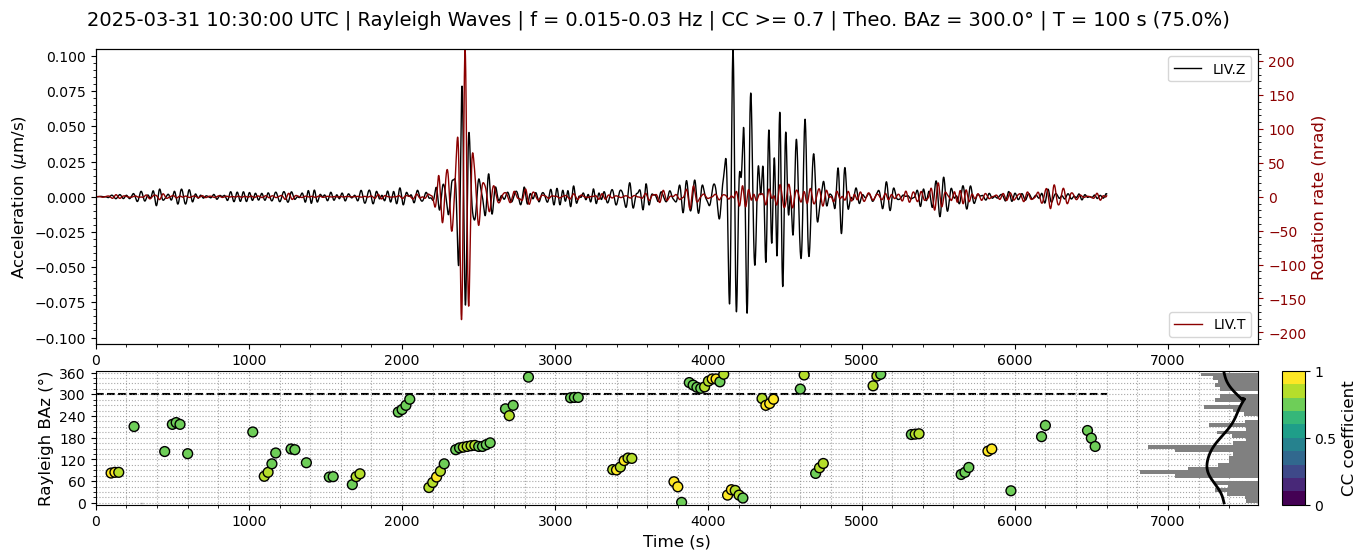

In [38]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='mid',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}tornado_backazimuth_mid.png", bbox_inches='tight')

### Estimate Phase Velocities

In [39]:
# estimate phase velocities
results_vel = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=T,
    overlap=0.5,
    baz=ev['backazimuth'],
)

fig.savefig(f"{config['path_to_figures']}tornado_velocities.png", bbox_inches='tight')

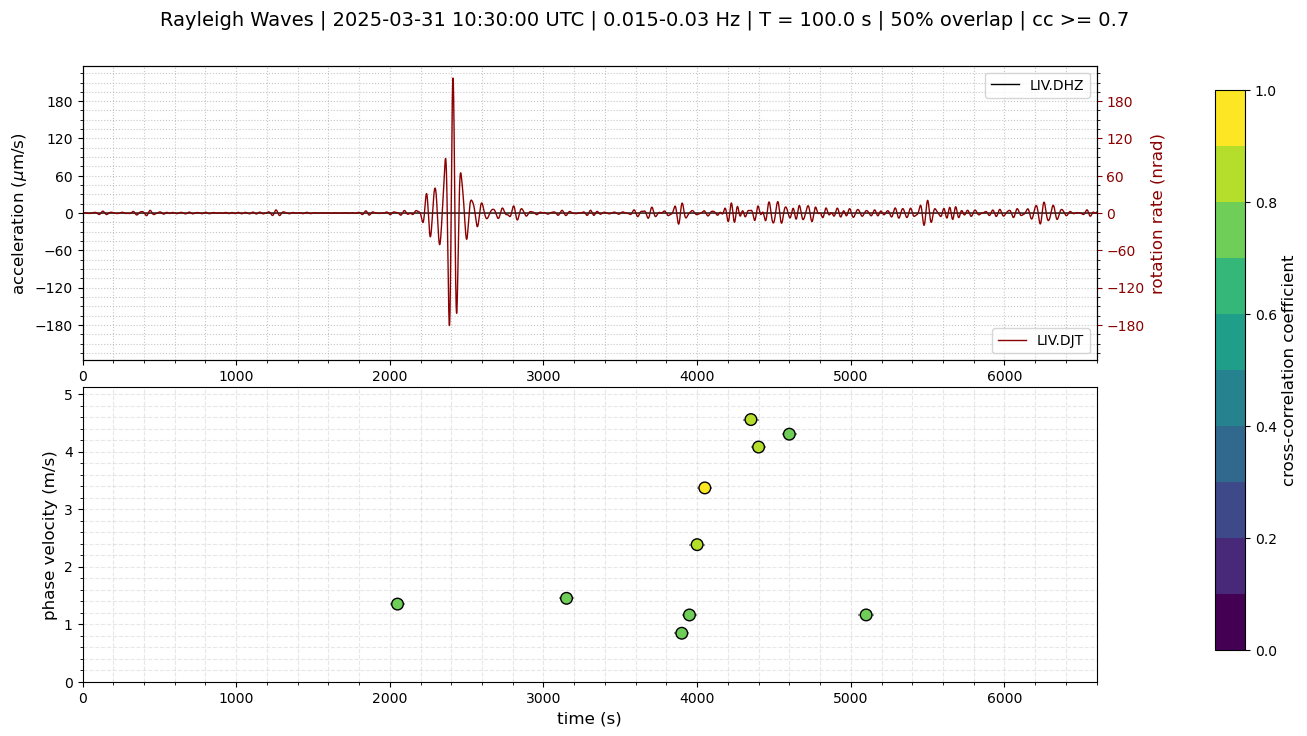

In [40]:
sd.plot_velocities(results_vel, cc_threshold=0.7);

### Animate Waveforms

In [27]:
from utils import animate_waveforms

Using backazimuth: 300.0°
3 Trace(s) in Stream:
XX.LIV..BJZ | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJR | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJT | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples 3 Trace(s) in Stream:
XX.LIV..BHZ | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BHR | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
XX.LIV..BJT | 2025-03-31T10:33:20.000000Z - 2025-03-31T12:23:20.000000Z | 20.0 Hz, 132001 samples
Animation parameters:
Duration: 6600.00s
Time step: 10.000s
Number of frames: 660
Frame rate: 0.1 fps
No event information available. Run get_event_info first.
No event information available. Run get_event_info first.


TypeError: 'NoneType' object cannot be interpreted as an integer

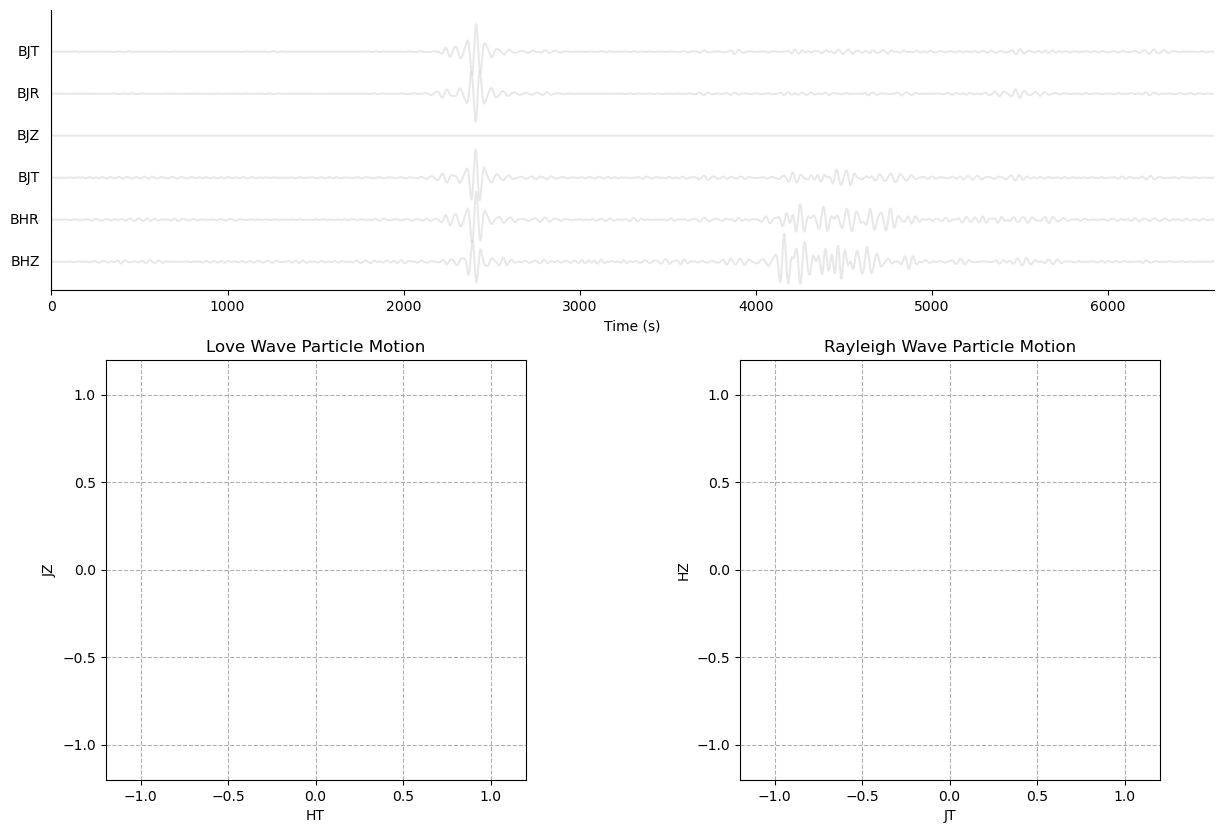

In [28]:
# Basic usage (displays animation)
animate_waveforms(sd,
                  time_step=10,
                  show_arrivals=True,
                  rotate_zrt=True,
                  baz=ev['backazimuth'],
                  save_path="./figures/animation.mp4")